# Improving ExtraSensory Context Recognition Without Subject Leakage

A gated, user-independent comparison of temporal, multi-task, robust, and ensemble methods on the ExtraSensory paper protocol.

## tl;dr

The promoted **causal TCN** reaches **0.798** macro balanced accuracy on the official five-fold evaluation, versus **0.768** for the existing paper logistic-regression reproduction, a benchmark gain of **+0.030**. On the sealed audit fold, the paired gain over threshold-tuned logistic regression is **+0.016** (95% user-cluster bootstrap CI **[-0.008, +0.037]**). The interval crosses zero, so the audit supports the preregistered point-estimate gate but is not independently conclusive with only 12 users.

The sensor-gated mixture of experts is even stronger on development folds (0.795), but remains a development-only lead: the TCN had already consumed the one promotion fold, so promoting MoE afterward would be repeated holdout testing. Its missing-sensor degradation reduction was only 10.3%, below the preregistered 20% gate, so reconstruction pretraining was not escalated.

## Context & Methods

The original 2017 system fits one class-balanced logistic classifier
per label on independent minutes. This study tests whether causal
temporal context, shared multi-label representations, and
sensor-specialized experts add signal while preserving the paper's
user-independent evaluation.

The workflow is deliberately gated:

1. Development uses official folds 0–2 with short three-epoch neural
   screens and config-only, single-coordinate mutations.
2. One selected family may use fold 4 for promotion at 12 epochs.
3. A passing promotion unlocks the sealed fold-3 audit.
4. Only a passing audit unlocks the official five-fold run.

Selection requires macro balanced-accuracy improvement while bounding
calibration and low-performing-user regressions. Every train/test split
is user-disjoint; causal histories are reset across users and gaps
longer than 90 seconds.

### Key Assumptions

1. The legacy-negative label policy is retained so results remain
   comparable with the reproduced 2017 target.
2. The archived one-minute features are the unit of analysis. The TCN
   models up to 30 prior contiguous minutes, but it cannot recover
   information absent from the public precomputed features.

In [1]:

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent
RESULTS = ROOT / "results" / "research"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

models = pd.read_csv(RESULTS / "model_comparison.csv")
ablations = pd.read_csv(RESULTS / "ablation_comparison.csv")
missing = pd.read_csv(RESULTS / "missing_sensor_comparison.csv")
per_label = pd.read_csv(RESULTS / "official_per_label_comparison.csv")
capabilities = pd.read_csv(RESULTS / "capability_matrix.csv")
findings = json.loads((RESULTS / "final_findings.json").read_text())


## Data

In [2]:

profile = json.loads((ROOT / "results" / "data_profile.json").read_text())
data_checks = pd.DataFrame(
    {
        "quantity": [
            "participants",
            "labeled minutes",
            "six-sensor evaluation minutes",
            "six-sensor participants",
            "input features",
        ],
        "value": [
            profile["users"],
            profile["paper_labeled_examples"],
            profile["core_complete_examples"],
            profile["core_complete_users"],
            profile["core_features"],
        ],
    }
)
display(data_checks)
assert data_checks["value"].tolist() == [60, 308320, 176941, 51, 175]
print("All official-population checks match the paper reproduction.")


,quantity,value
0,participants,60
1,labeled minutes,308320
2,six-sensor evaluation minutes,176941
3,six-sensor participants,51
4,input features,175


All official-population checks match the paper reproduction.


## Results

In [3]:

official = models.query(
    "stage == 'official' and model != "
    "'Paper logistic regression reproduction'"
).copy()
display(
    official[
        [
            "model",
            "macro_balanced_accuracy",
            "macro_ece",
            "user_macro_class_recall_p20",
            "elapsed_seconds",
        ]
    ].style.format(
        {
            "macro_balanced_accuracy": "{:.3f}",
            "macro_ece": "{:.3f}",
            "user_macro_class_recall_p20": "{:.3f}",
            "elapsed_seconds": "{:.1f}",
        }
    )
)

primary = findings["primary_finding"]
assert np.isclose(
    primary["official_delta"],
    primary["official_candidate_macro_balanced_accuracy"]
    - primary["official_baseline_macro_balanced_accuracy"],
)
print(
    "Official benchmark delta versus the paper LR reproduction:",
    f"{primary['official_delta']:+.4f}",
)
audit = findings["paired_audit_finding"]
print(
    "Paired sealed-audit delta:",
    f"{audit['delta']:+.4f}",
    "95% user-cluster CI:",
    tuple(round(value, 4) for value in audit["user_cluster_bootstrap_95_ci"]),
)
print(primary["comparison_note"])
print(primary["execution_note"])


,model,macro_balanced_accuracy,macro_ece,user_macro_class_recall_p20,elapsed_seconds
10,Causal TCN,0.798,0.077,0.764,333.6


Official benchmark delta versus the paper LR reproduction: +0.0296
Paired sealed-audit delta: +0.0159 95% user-cluster CI: (-0.0085, 0.0372)
The tracked paper reproduction retained metrics but not row-level probabilities, so a paired official confidence interval cannot be computed without refitting it.
A threshold-tuned five-fold refit was terminated after a rare-label liblinear job exceeded four hours. No output from that attempt is used in the report.


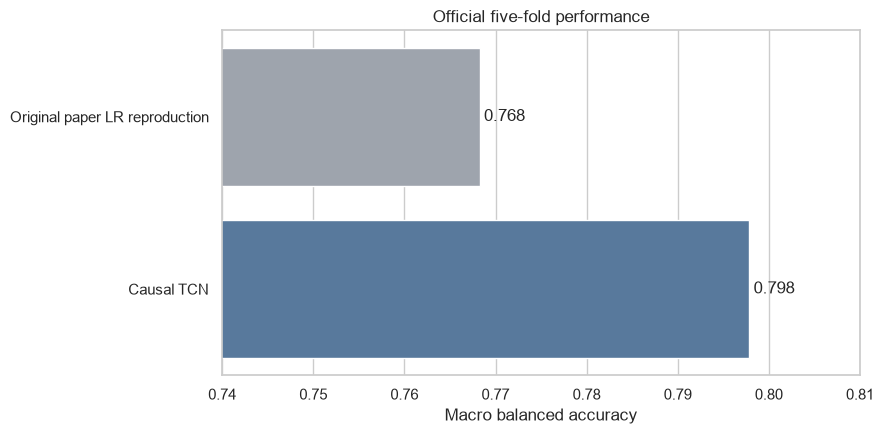

In [4]:

plot_official = pd.concat(
    [
        pd.DataFrame(
            {
                "model": ["Original paper LR reproduction"],
                "macro_balanced_accuracy": [
                    float(
                        pd.read_csv(ROOT / "results" / "model_averages.csv")
                        .query("model == 'EF'")
                        ["macro_balanced_accuracy"]
                        .iloc[0]
                    )
                ],
            }
        ),
        official[["model", "macro_balanced_accuracy"]],
    ],
    ignore_index=True,
)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(
    data=plot_official,
    x="macro_balanced_accuracy",
    y="model",
    hue="model",
    legend=False,
    palette=["#9ca3af", "#4c78a8"],
    ax=ax,
)
ax.set_xlim(0.74, 0.81)
ax.set_xlabel("Macro balanced accuracy")
ax.set_ylabel("")
ax.set_title("Official five-fold performance")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
fig.tight_layout()
fig.savefig(FIGURES / "official_model_comparison.png", dpi=160)
plt.show()


### Evidence gates

The table separates stages intentionally. Development is for choosing ideas; promotion and audit are single-use checks, not extra tuning data.

In [5]:

gates = pd.DataFrame(
    [
        {
            "stage": stage,
            "candidate": row["candidate"],
            "baseline": row["baseline"],
            "delta": row["candidate"] - row["baseline"],
        }
        for stage, row in {
            "development": {
                "candidate": float(
                    models.query(
                        "stage == 'development' and model == 'Causal TCN'"
                    )["macro_balanced_accuracy"].iloc[0]
                ),
                "baseline": float(
                    models.query(
                        "stage == 'development' and "
                        "model == 'Threshold-tuned logistic regression'"
                    )["macro_balanced_accuracy"].iloc[0]
                ),
            },
            "promotion": {
                "candidate": float(
                    models.query(
                        "stage == 'promotion' and model == 'Causal TCN'"
                    )["macro_balanced_accuracy"].iloc[0]
                ),
                "baseline": float(
                    models.query(
                        "stage == 'promotion' and "
                        "model == 'Threshold-tuned logistic regression'"
                    )["macro_balanced_accuracy"].iloc[0]
                ),
            },
            "audit": {
                "candidate": float(
                    models.query(
                        "stage == 'audit' and model == 'Causal TCN'"
                    )["macro_balanced_accuracy"].iloc[0]
                ),
                "baseline": float(
                    models.query(
                        "stage == 'audit' and "
                        "model == 'Threshold-tuned logistic regression'"
                    )["macro_balanced_accuracy"].iloc[0]
                ),
            },
            "official": {
                "candidate": primary[
                    "official_candidate_macro_balanced_accuracy"
                ],
                "baseline": primary[
                    "official_baseline_macro_balanced_accuracy"
                ],
            },
        }.items()
    ]
)
display(gates.style.format({column: "{:.3f}" for column in gates.columns[1:]}))


,stage,candidate,baseline,delta
0,development,0.782,0.749,0.032
1,promotion,0.750,0.739,0.011
2,audit,0.790,0.774,0.016
3,official,0.798,0.768,0.030


### What helped on development folds

,model,macro_balanced_accuracy,macro_ece,user_macro_class_recall_p20,protocol_note
4,Sensor-gated mixture of experts,0.795,0.092,0.762,Promising development-only result; not promoted because the TCN had already consumed the single promotion fold.
2,Multi-task MLP,0.788,0.114,0.760,nan
3,Causal TCN,0.782,0.076,0.767,nan
1,Threshold-tuned logistic regression,0.749,0.106,0.734,nan
5,Classifier chain,0.665,0.075,0.729,nan


/var/folders/q2/r1drc57n6xd03gr53prd043hwb05q1/T/ipykernel_29630/1905932068.py:23: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#4c78a8'` for the same effect.

  sns.barplot(


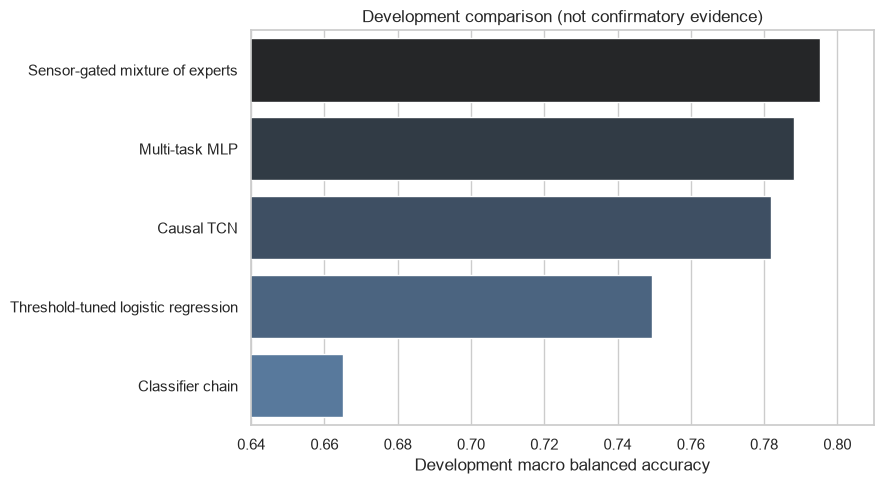

In [6]:

development = models.query("stage == 'development'").sort_values(
    "macro_balanced_accuracy", ascending=False
)
display(
    development[
        [
            "model",
            "macro_balanced_accuracy",
            "macro_ece",
            "user_macro_class_recall_p20",
            "protocol_note",
        ]
    ].style.format(
        {
            "macro_balanced_accuracy": "{:.3f}",
            "macro_ece": "{:.3f}",
            "user_macro_class_recall_p20": "{:.3f}",
        }
    )
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=development,
    x="macro_balanced_accuracy",
    y="model",
    hue="model",
    legend=False,
    color="#4c78a8",
    ax=ax,
)
ax.set_xlim(0.64, 0.81)
ax.set_xlabel("Development macro balanced accuracy")
ax.set_ylabel("")
ax.set_title("Development comparison (not confirmatory evidence)")
fig.tight_layout()
fig.savefig(FIGURES / "development_model_comparison.png", dpi=160)
plt.show()


### Temporal and robustness ablations

In [7]:

display(
    ablations.sort_values("macro_balanced_accuracy", ascending=False).style.format(
        {
            "macro_balanced_accuracy": "{:.3f}",
            "delta_vs_default_tcn": "{:+.3f}",
            "macro_ece": "{:.3f}",
            "user_macro_class_recall_p20": "{:.3f}",
            "elapsed_seconds": "{:.1f}",
        }
    )
)
print(
    "The 30-minute history matters; label refinement is effectively neutral. "
    "GroupDRO raises aggregate BA slightly but lowers the user P20 metric, "
    "so it does not clearly achieve its robustness objective."
)


,variant,macro_balanced_accuracy,delta_vs_default_tcn,macro_ece,user_macro_class_recall_p20,elapsed_seconds,run_id
3,GroupDRO,0.785,+0.003,0.084,0.753,157.5,ablation-causal_tcn_group_dro-99da4b3e188f-development
0,Causal TCN,0.782,+0.000,0.076,0.767,134.3,causal-tcn-local-screening-base-b08c24a2d043-development
1,No label refinement,0.782,-0.000,0.076,0.767,136.5,ablation-causal_tcn_no_label_refinement-1158d5f0ac77-development
2,Short history (5 minutes),0.774,-0.008,0.089,0.763,89.3,ablation-causal_tcn_short_history-a249de717878-development
4,Asymmetric loss,0.766,-0.015,0.123,0.746,131.4,causal-tcn-local-trial-00-asymmetric_gamma_negative-5d61218ae2e3-development


The 30-minute history matters; label refinement is effectively neutral. GroupDRO raises aggregate BA slightly but lowers the user P20 metric, so it does not clearly achieve its robustness objective.


### Per-label official effects

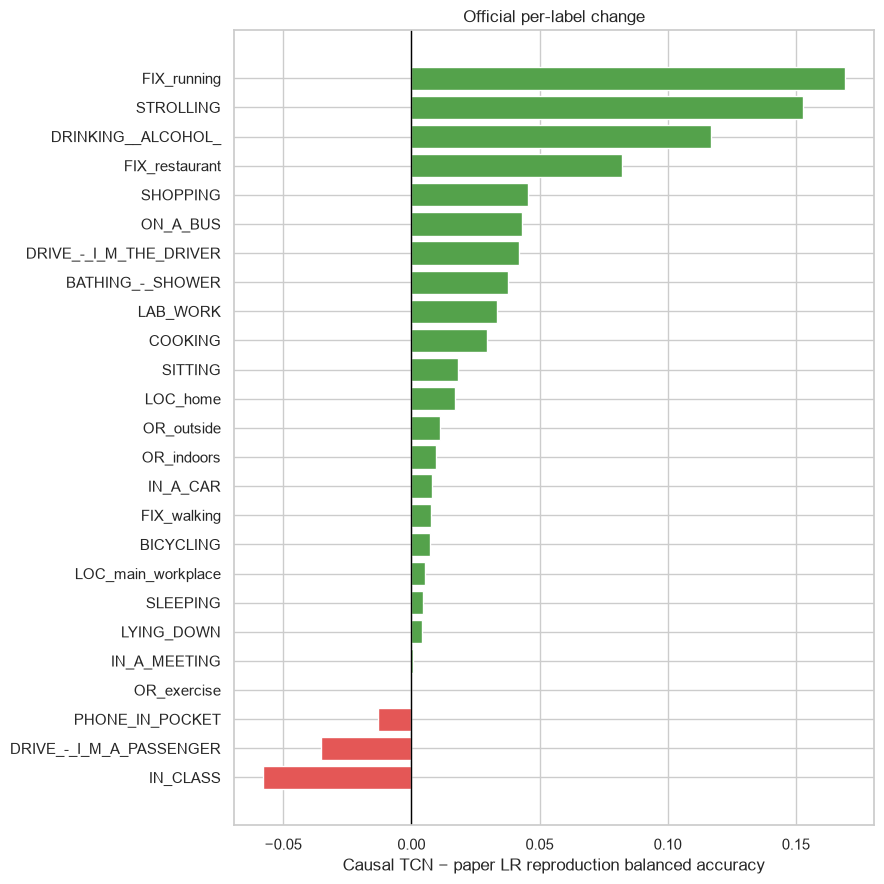

,label,causal_tcn_balanced_accuracy,paper_lr_reproduction_balanced_accuracy,delta
7,IN_CLASS,0.645,0.703,-0.058
15,DRIVE_-_I_M_A_PASSENGER,0.798,0.833,-0.035
18,PHONE_IN_POCKET,0.755,0.768,-0.013
19,OR_exercise,0.815,0.815,-0.000
8,IN_A_MEETING,0.806,0.805,+0.001
21,SHOPPING,0.724,0.678,+0.045
17,FIX_restaurant,0.845,0.763,+0.082
23,DRINKING__ALCOHOL_,0.813,0.696,+0.117
22,STROLLING,0.800,0.647,+0.153
3,FIX_running,0.789,0.620,+0.169


In [8]:

ordered = per_label.sort_values("delta")
fig, ax = plt.subplots(figsize=(9, 9))
colors = np.where(ordered["delta"] >= 0, "#54a24b", "#e45756")
ax.barh(ordered["label"], ordered["delta"], color=colors)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Causal TCN − paper LR reproduction balanced accuracy")
ax.set_title("Official per-label change")
fig.tight_layout()
fig.savefig(FIGURES / "official_per_label_delta.png", dpi=160)
plt.show()
display(
    pd.concat([ordered.head(5), ordered.tail(5)])
    .sort_values("delta")
    .style.format(
        {
            "causal_tcn_balanced_accuracy": "{:.3f}",
            "paper_lr_reproduction_balanced_accuracy": "{:.3f}",
            "delta": "{:+.3f}",
        }
    )
)


### Missing-sensor robustness

,model,average_degradation
0,Causal TCN,0.030
1,Sensor-gated mixture of experts,0.027


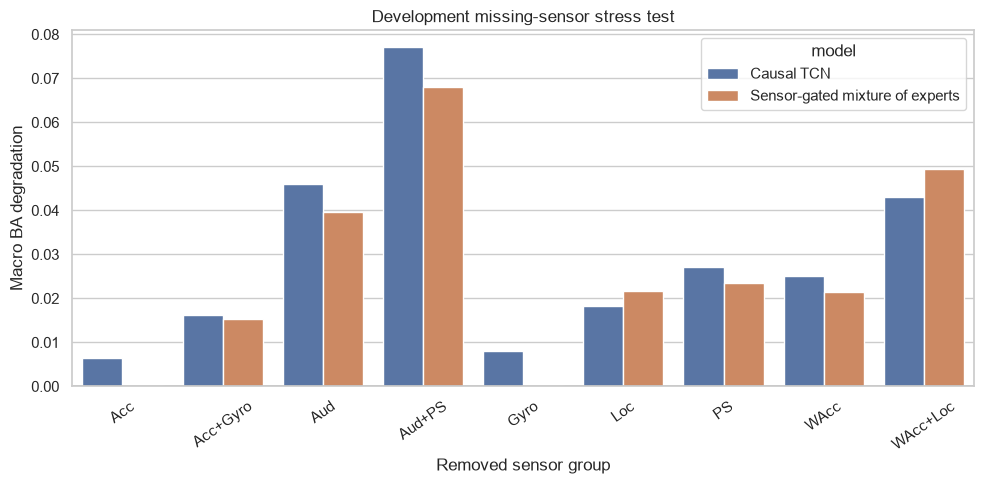

In [9]:

development_missing = missing.query("stage == 'development'").copy()
robustness = (
    development_missing.groupby("model", as_index=False)["degradation"]
    .mean()
    .rename(columns={"degradation": "average_degradation"})
)
display(robustness.style.format({"average_degradation": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=development_missing,
    x="missing_sensor_group",
    y="degradation",
    hue="model",
    ax=ax,
)
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Macro BA degradation")
ax.set_xlabel("Removed sensor group")
ax.set_title("Development missing-sensor stress test")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(FIGURES / "missing_sensor_robustness.png", dpi=160)
plt.show()


### Implemented versus executed

In [10]:

display(capabilities)
print(
    "Implementation-only entries are not claimed as empirical wins. "
    "They remain available for a future compute-authorized study."
)


,method,implemented,full_experiment_executed,evidence
0,Paper logistic regression,True,True,official
1,Threshold-tuned logistic regression,True,True,"development, promotion, sealed audit"
2,Elastic-net logistic regression,True,False,not run: compute budget
3,Histogram gradient boosting,True,False,not run: compute budget
4,Classifier chain,True,True,development
5,Multi-task MLP,True,True,development
6,Causal TCN,True,True,official
7,GroupDRO,True,True,development ablation
8,Asymmetric loss,True,True,development ablation
9,Sensor-gated mixture of experts,True,True,development


Implementation-only entries are not claimed as empirical wins. They remain available for a future compute-authorized study.


## Takeaways

- The official five-fold causal TCN score is **+0.030**
  above the existing paper logistic-regression reproduction. This is a
  benchmark comparison, not a paired confidence interval, because the
  earlier reproduction did not retain row-level probabilities.
- Against threshold-tuned logistic regression on the sealed audit,
  the TCN improves the point estimate, calibration, and low-user P20.
  Its 12-user cluster-bootstrap interval crosses zero, so uncertainty
  remains and the result is not independently conclusive.
- A 30-minute causal history carries useful information; shortening it
  to five minutes costs about 0.008 macro BA. The low-rank label
  refinement layer adds essentially nothing here.
- The mixture of experts is the best development result, but it is
  **not** a confirmed winner. A clean follow-up must start with a fresh
  promotion protocol or an external dataset.
- The missing-sensor robustness gate prevented an unsupported SSL
  escalation. This is a useful negative result: more machinery was not
  allowed to consume confirmatory evaluation merely because it existed.

The main practical value is therefore specific: temporal modeling of
contiguous, user-safe minute histories improves the ExtraSensory
benchmark. Claims about MoE superiority, general deployment robustness,
or real-time raw-sensor systems require new confirmatory evidence.